# Bài 3 (Trang 7) – Neural Network trên MNIST (k-fold cross validation)

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Câu a) Đọc bộ dữ liệu MNIST từ Keras

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense, Dropout
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
tf.get_logger().setLevel("ERROR")  # ẩn cảnh báo không có GPU
keras.utils.set_random_seed(42)
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc MNIST")

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Đã đọc MNIST


## Câu b) Kích thước tập train, test

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print("train_images:", train_images.shape, "train_labels:", train_labels.shape)
print("test_images:", test_images.shape, "test_labels:", test_labels.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
train_images: (60000, 28, 28) train_labels: (60000,)
test_images: (10000, 28, 28) test_labels: (10000,)


## Câu c) Chuẩn hóa pixel về [0,1]

In [3]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Min:", train_images.min(), "Max:", train_images.max())

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Min: 0.0 Max: 1.0


## Câu d) Hàm create_model

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.2),
        Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

create_model().summary()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu e) Huấn luyện bằng k-fold cross validation (k=10)
Mỗi fold: train 5 epoch, batch_size 32; lưu model vào mảng `models` và file `models/mnist_fold_<i>.keras`.

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
models, accuracy_per_fold, loss_per_fold = [], [], []
os.makedirs("models", exist_ok=True)

for fold, (train_index, val_index) in enumerate(kfold.split(train_images), start=1):
    model = create_model()
    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]
    model.fit(X_train_fold, y_train_fold, epochs=5, batch_size=32,
              validation_data=(X_val_fold, y_val_fold), verbose=0)
    models.append(model)
    model.save(f"models/mnist_fold_{fold}.keras")
    loss, acc = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    accuracy_per_fold.append(acc); loss_per_fold.append(loss)
    print(f"Fold {fold:2d}: loss = {loss:.4f} - accuracy = {acc:.4f}")

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Fold  1: loss = 0.0716 - accuracy = 0.9780
Fold  2: loss = 0.0997 - accuracy = 0.9712
Fold  3: loss = 0.0922 - accuracy = 0.9723
Fold  4: loss = 0.0817 - accuracy = 0.9755
Fold  5: loss = 0.1004 - accuracy = 0.9707
Fold  6: loss = 0.0881 - accuracy = 0.9752
Fold  7: loss = 0.0919 - accuracy = 0.9725
Fold  8: loss = 0.0861 - accuracy = 0.9742
Fold  9: loss = 0.0980 - accuracy = 0.9707
Fold 10: loss = 0.0822 - accuracy = 0.9748


## Câu f) Mean / Std của Accuracy và Loss

In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print(f"Mean Accuracy: {np.mean(accuracy_per_fold):.4f}")
print(f"Std Accuracy : {np.std(accuracy_per_fold):.4f}")
print(f"Mean Loss    : {np.mean(loss_per_fold):.4f}")
print(f"Std Loss     : {np.std(loss_per_fold):.4f}")

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Mean Accuracy: 0.9735
Std Accuracy : 0.0023
Mean Loss    : 0.0892
Std Loss     : 0.0087


## Câu g) Biểu đồ accuracy, loss sau mỗi fold

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


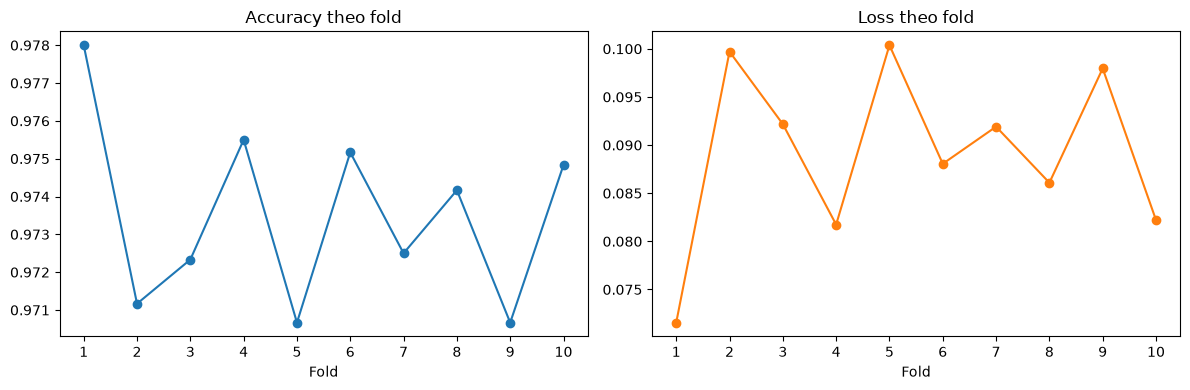

In [7]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
folds = range(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(folds, accuracy_per_fold, "o-"); ax[0].set_title("Accuracy theo fold")
ax[0].set_xlabel("Fold"); ax[0].set_xticks(list(folds))
ax[1].plot(folds, loss_per_fold, "o-", color="tab:orange"); ax[1].set_title("Loss theo fold")
ax[1].set_xlabel("Fold"); ax[1].set_xticks(list(folds))
plt.tight_layout(); plt.show()

## Câu h) Dùng mô hình có Accuracy tốt nhất phân lớp tập test

In [8]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
index = int(np.argmax(accuracy_per_fold))
best_model = models[index]
print(f"Fold tốt nhất: {index + 1} (accuracy validation = {accuracy_per_fold[index]:.4f})")
y_pred = np.argmax(best_model.predict(test_images, verbose=0), axis=1)
print("10 nhãn dự đoán đầu:", y_pred[:10])

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Fold tốt nhất: 1 (accuracy validation = 0.9780)
10 nhãn dự đoán đầu: [7 2 1 0 4 1 4 9 5 9]


## Câu i) Accuracy trên tập test

In [9]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print("Accuracy trên tập test:", round(accuracy_score(test_labels, y_pred), 4))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Accuracy trên tập test: 0.9764


## Câu j) Precision, Recall, F1-score

In [10]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print(classification_report(test_labels, y_pred, digits=4))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
              precision    recall  f1-score   support

           0     0.9720    0.9929    0.9823       980
           1     0.9860    0.9921    0.9890      1135
           2     0.9683    0.9767    0.9725      1032
           3     0.9760    0.9663    0.9711      1010
           4     0.9816    0.9766    0.9791       982
           5     0.9720    0.9742    0.9731       892
           6     0.9793    0.9854    0.9823       958
           7     0.9719    0.9747    0.9733      1028
           8     0.9821    0.9589    0.9704       974
           9     0.9740    0.9643    0.9691      1009

    accuracy                         0.9764     10000
   macro avg     0.9763    0.9762    0.9762     10000
weighted avg     0.9764    0.9764    0.9764     10000



## Câu k) Confusion matrix (heatmap)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


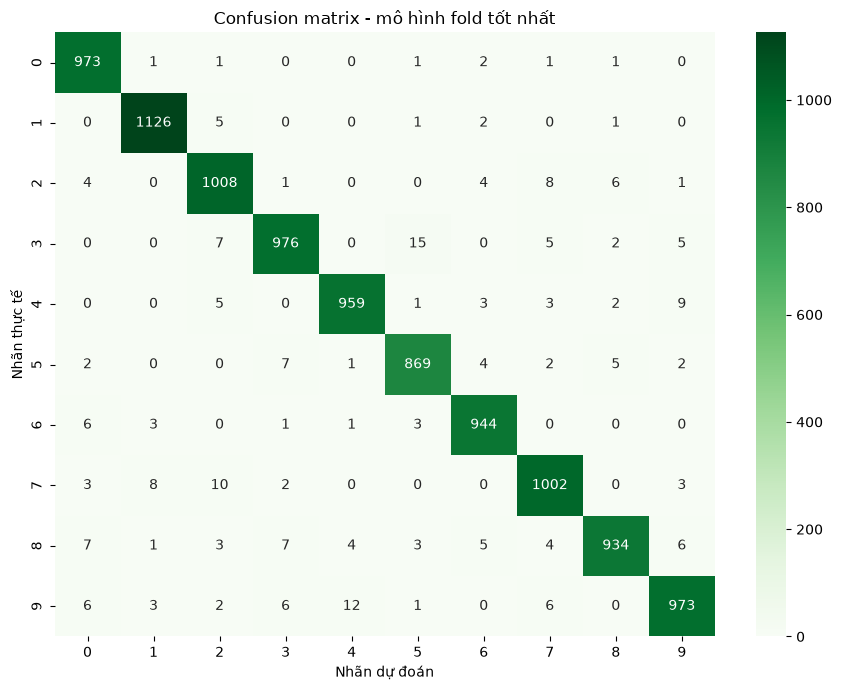

In [11]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn thực tế"); plt.title("Confusion matrix - mô hình fold tốt nhất")
plt.tight_layout(); plt.show()

## Câu l) Kết quả phân lớp 5 ảnh đầu tiên của tập test

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Ảnh 0: dự đoán = 7, thực tế = 7
Ảnh 1: dự đoán = 2, thực tế = 2
Ảnh 2: dự đoán = 1, thực tế = 1
Ảnh 3: dự đoán = 0, thực tế = 0
Ảnh 4: dự đoán = 4, thực tế = 4


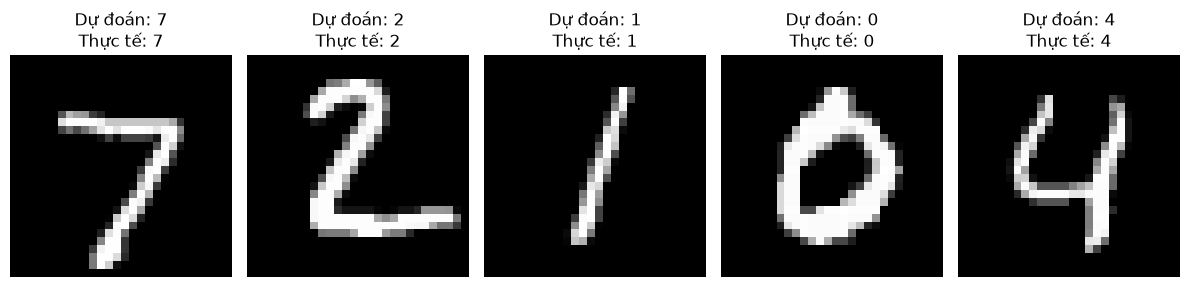

In [12]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
plt.figure(figsize=(12, 3))
for image_index in range(5):
    img = np.expand_dims(test_images[image_index], axis=0)
    pred = np.argmax(best_model.predict(img, verbose=0), axis=1)[0]
    print(f"Ảnh {image_index}: dự đoán = {pred}, thực tế = {test_labels[image_index]}")
    plt.subplot(1, 5, image_index + 1)
    plt.imshow(test_images[image_index], cmap="gray")
    plt.title(f"Dự đoán: {pred}\nThực tế: {test_labels[image_index]}")
    plt.axis("off")
plt.tight_layout(); plt.show()